- Nama: Muhammad Putra Harifin Pane
- Email: putraharifin@gmail.com
- id Dicoding: putraharifin25

## Persiapan

Menyiapkan library

In [ ]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [ ]:
DATA_PATH = "/content/employee_data.csv"

df = pd.read_csv(DATA_PATH)

print("=" * 60)
print("DATASET HR ANALYTICS")
print("=" * 60)
print("Ukuran dataset:", df.shape)
display(df.head())

DATASET HR ANALYTICS
Ukuran dataset: (1470, 35)


,EmployeeId,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,1,38,NaN,Travel_Frequently,1444,Human Resources,1,4,Other,1,4,Male,88,3,1,Human Resources,2,Married,2991,5224,0,Y,Yes,11,3,2,80,1,7,2,3,6,2,1,2
1,2,37,1.0,Travel_Rarely,1141,Research & Development,11,2,Medical,1,1,Female,61,1,2,Healthcare Representative,2,Married,4777,14382,5,Y,No,15,3,1,80,0,15,2,1,1,0,0,0
2,3,51,1.0,Travel_Rarely,1323,Research & Development,4,4,Life Sciences,1,1,Male,34,3,1,Research Scientist,3,Married,2461,10332,9,Y,Yes,12,3,3,80,3,18,2,4,10,0,2,7
3,4,42,0.0,Travel_Frequently,555,Sales,26,3,Marketing,1,3,Female,77,3,4,Sales Executive,2,Married,13525,14864,5,Y,No,14,3,4,80,1,23,2,4,20,4,4,8
4,5,40,NaN,Travel_Rarely,1194,Research & Development,2,4,Medical,1,3,Female,98,3,1,Research Scientist,3,Married,2001,12549,2,Y,No,14,3,2,80,3,20,2,3,5,3,0,2


Insight: Dataset memiliki 1.470 baris dan 35 kolom

## Data Understanding

In [ ]:
print("\n--- Informasi Dataset ---")
df.info()


--- Informasi Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   EmployeeId                1470 non-null   int64  
 1   Age                       1470 non-null   int64  
 2   Attrition                 1058 non-null   float64
 3   BusinessTravel            1470 non-null   object 
 4   DailyRate                 1470 non-null   int64  
 5   Department                1470 non-null   object 
 6   DistanceFromHome          1470 non-null   int64  
 7   Education                 1470 non-null   int64  
 8   EducationField            1470 non-null   object 
 9   EmployeeCount             1470 non-null   int64  
 10  EnvironmentSatisfaction   1470 non-null   int64  
 11  Gender                    1470 non-null   object 
 12  HourlyRate                1470 non-null   int64  
 13  JobInvolvement            1470 non-n

**Insight:**

* **Data Hilang pada Target Variabel (Missing Values):** Kolom Attrition memiliki 412 data kosong (hanya ada 1058 data dari total 1470 baris). Ini mengindikasikan adanya data test set yang belum diberi label, atau data karyawan aktif saat ini yang perlu dipisahkan atau diisi sebelum melatih model machine learning.
* **Kombinasi Tipe Data Variatif:** Dataset terdiri dari 26 fitur numerik (int64), 8 fitur kategorikal (object), dan 1 target variabel (float64), yang membutuhkan strategi preprocessing berbeda seperti encoding (untuk fitur kategorikal) dan kalkulasi statistik korelasi (untuk fitur numerik).
* **Potensi Fitur Redundan (Constant Features):** Kolom seperti EmployeeCount dan StandardHours biasanya bernilai konstan untuk semua karyawan (misal: EmployeeCount selalu 1 dan StandardHours selalu 80). Perlu dicek variansinya pada tahap pembersihan data karena fitur yang konstan tidak memberikan informasi bagi model prediktif.
* **Kekayaan Fitur Pengalaman & Kepuasan:** Dataset ini memiliki informasi yang sangat kaya terkait indikator psikologis karyawan (seperti EnvironmentSatisfaction, JobInvolvement, JobSatisfaction, WorkLifeBalance) dan indikator retensi (seperti YearsAtCompany, YearsWithCurrManager, YearsSinceLastPromotion). Gabungan fitur-fitur ini sangat potensial untuk menemukan pola tersembunyi penyebab utama tingginya angka attrition.


In [ ]:
print("\n--- Statistik Deskriptif ---")
display(df.describe(include="all").T)


--- Statistik Deskriptif ---


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
EmployeeId,1470.0,NaN,NaN,NaN,735.5,424.496761,1.0,368.25,735.5,1102.75,1470.0
Age,1470.0,NaN,NaN,NaN,36.92381,9.135373,18.0,30.0,36.0,43.0,60.0
Attrition,1058.0,NaN,NaN,NaN,0.169187,0.375094,0.0,0.0,0.0,0.0,1.0
BusinessTravel,1470,3,Travel_Rarely,1043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DailyRate,1470.0,NaN,NaN,NaN,802.485714,403.5091,102.0,465.0,802.0,1157.0,1499.0
Department,1470,3,Research & Development,961,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DistanceFromHome,1470.0,NaN,NaN,NaN,9.192517,8.106864,1.0,2.0,7.0,14.0,29.0
Education,1470.0,NaN,NaN,NaN,2.912925,1.024165,1.0,2.0,3.0,4.0,5.0
EducationField,1470,6,Life Sciences,606,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EmployeeCount,1470.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0


**Insight:**

* **Tingkat Attrition Melebihi Batas Toleransi:** Dari 1058 karyawan yang terlabeli, rata-rata attrition berada di angka **16.9% (mean = 0.1691)**. Angka ini secara signifikan melampaui batas toleransi 10% yang ditetapkan departemen HR Jaya Jaya Maju, mengonfirmasi urgensi penanganan masalah ini.
* **Fitur Konstan Terdeteksi (Redundan):** Kolom **EmployeeCount** (std = 0.0, mean/min/max = 1.0) dan **StandardHours** (std = 0.0, mean/min/max = 80.0) memiliki variansi nol, sedangkan **Over18** hanya memiliki 1 nilai unik ('Y'). Ketiga fitur ini sebaiknya dihapus (*dropped*) karena tidak memberikan informasi apa pun bagi model machine learning.
* **Kesenjangan Pendapatan yang Tinggi (Skewed Income):** Nilai median (50%) untuk **MonthlyIncome** adalah $4,919, sementara nilai maksimumnya mencapai  $19,999 dengan standar deviasi yang besar ($4,707). Hal ini mengindikasikan distribusi pendapatan condong ke kanan (*right-skewed*), di mana mayoritas karyawan berada di level pendapatan rendah hingga menengah.
* **Karakteristik Demografi dan Domisili:** Rata-rata usia karyawan berada di angka **36.9 tahun** dengan mayoritas karyawan berjenis kelamin laki-laki (882 dari 1470) dan berstatus menikah (673 dari 1470). Jarak rumah ke kantor (**DistanceFromHome**) memiliki median 7 km, namun ada karyawan yang tinggal hingga sejauh 29 km, yang berpotensi memengaruhi kenyamanan kerja.
* **Metrik Retensi dan Masa Kerja Karyawan:** Mayoritas karyawan memiliki loyalitas moderat dengan median **5 tahun di perusahaan (YearsAtCompany)** dan 3 tahun di posisi yang sama serta di bawah manajer yang sama. Namun, terdapat indikasi stagnasi karier bagi sebagian karyawan karena nilai maksimal **YearsSinceLastPromotion** mencapai 15 tahun tanpa promosi.


In [ ]:
quality_summary = pd.DataFrame({
    "Tipe_Data": df.dtypes.astype(str),
    "Jumlah_Missing": df.isna().sum(),
    "Persentase_Missing": (df.isna().mean() * 100).round(2),
    "Jumlah_Nilai_Unik": df.nunique(dropna=True)
})

print("\n--- Kualitas Data ---")
display(quality_summary.sort_values(
    "Persentase_Missing",
    ascending=False
))

print("\nJumlah baris duplikat:", df.duplicated().sum())

if "EmployeeId" in df.columns:
    print(
        "Jumlah EmployeeId duplikat:",
        df["EmployeeId"].duplicated().sum()
    )

constant_columns = [
    col for col in df.columns
    if df[col].nunique(dropna=False) <= 1
]

print("\nKolom konstan:", constant_columns)



--- Kualitas Data ---


,Tipe_Data,Jumlah_Missing,Persentase_Missing,Jumlah_Nilai_Unik
Attrition,float64,412,28.03,2
EmployeeId,int64,0,0.00,1470
Age,int64,0,0.00,43
BusinessTravel,object,0,0.00,3
DailyRate,int64,0,0.00,886
Department,object,0,0.00,3
DistanceFromHome,int64,0,0.00,29
Education,int64,0,0.00,5
EducationField,object,0,0.00,6
EmployeeCount,int64,0,0.00,1



Jumlah baris duplikat: 0
Jumlah EmployeeId duplikat: 0

Kolom konstan: ['EmployeeCount', 'Over18', 'StandardHours']


**Insight:**

* **Data Hilang Hanya pada Variabel Target:** Kolom **Attrition** merupakan satu-satunya kolom yang memiliki *missing values* sebesar **28.03% (412 baris)**. Seluruh 34 fitur lainnya bersih 100% dari data kosong, sehingga tidak diperlukan strategi imputasi nilai pada fitur-fitur independen.
* **Integritas Data Sangat Baik (No Duplicates):** Tidak ditemukan baris duplikat secara keseluruhan (**0 duplikat**), dan kolom **EmployeeId** terbukti memiliki nilai unik untuk setiap baris (0 duplikat dari 1470 data). Ini memastikan bahwa setiap baris mewakili data satu karyawan unik tanpa adanya redundansi pencatatan.
* **Konfirmasi Kolom Konstan (Zero Variance):** Analisis kualitas data secara otomatis mengidentifikasi tiga kolom konstan, yaitu **EmployeeCount, Over18, dan StandardHours** (memiliki Jumlah_Nilai_Unik = 1). Ketiga kolom ini wajib dihapus (*dropped*) pada tahap preprocessing karena tidak berkontribusi terhadap variansi data atau performa model prediksi.
* **Kekayaan Informasi pada Fitur Finansial:** Kolom **MonthlyRate** (1427 nilai unik) dan **MonthlyIncome** (1349 nilai unik) memiliki variasi nilai yang sangat tinggi mendekati jumlah baris data. Hal ini menunjukkan tingkat sensitivitas dan detail data finansial karyawan yang sangat baik untuk dieksplorasi lebih lanjut.



## Data Preparation / Preprocessing

MENYIAPKAN DATA UNTUK EDA


--- KPI Attrition ---
Total data berlabel : 1058
Karyawan keluar     : 179
Karyawan bertahan   : 879
Attrition rate      : 16.92%
Label Attrition kosong: 412


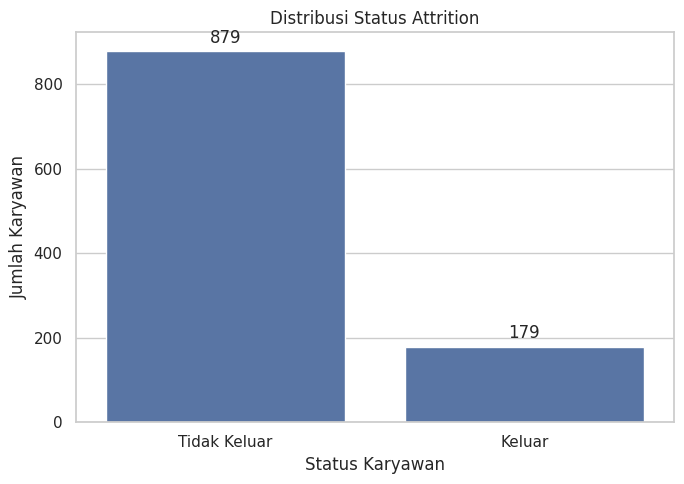

In [ ]:
if "Attrition" not in df.columns:
    raise ValueError("Dataset harus memiliki kolom Attrition.")

df_eda = df.loc[
    df["Attrition"].isin([0, 1])
].copy()

df_eda["Attrition"] = df_eda["Attrition"].astype(int)

if df_eda.empty:
    raise ValueError(
        "Tidak ditemukan baris dengan label Attrition 0 atau 1."
    )

total_labeled = len(df_eda)
total_left = int(df_eda["Attrition"].sum())
total_retained = total_labeled - total_left
attrition_rate = df_eda["Attrition"].mean() * 100

print("\n--- KPI Attrition ---")
print(f"Total data berlabel : {total_labeled}")
print(f"Karyawan keluar     : {total_left}")
print(f"Karyawan bertahan   : {total_retained}")
print(f"Attrition rate      : {attrition_rate:.2f}%")
print(
    "Label Attrition kosong:",
    int(df["Attrition"].isna().sum())
)

attrition_counts = (
    df_eda["Attrition"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

plt.figure(figsize=(7, 5))
ax = sns.barplot(
    x=["Tidak Keluar", "Keluar"],
    y=attrition_counts.values
)

ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
plt.title("Distribusi Status Attrition")
plt.xlabel("Status Karyawan")
plt.ylabel("Jumlah Karyawan")
plt.tight_layout()
plt.show()

**Insight:**

* **Ketidakseimbangan Kelas pada Data (Imbalanced Data):** Dari 1058 total data berlabel, terdapat **879 karyawan bertahan** dibandingkan dengan **179 karyawan keluar**. Perbandingan kelas yang timpang ini (sekitar 5:1) wajib diantisipasi saat membangun model machine learning dengan menggunakan teknik penyeimbangan data seperti SMOTE atau penyesuaian parameter class weight agar model tidak bias ke kelas mayoritas.
* **Tingkat Attrition Kritis Secara Bisnis:** Angka **Attrition Rate sebesar 16.92%** mengonfirmasi secara empiris bahwa tingkat perputaran karyawan di Jaya Jaya Maju berada di zona merah (jauh melampaui ambang batas toleransi HR sebesar 10%). Hal ini memperkuat urgensi pemantauan berkala dan implementasi strategi retensi berbasis data.
* **Validasi Dataset untuk Model:** Sebanyak **412 data dengan label Attrition kosong** berhasil dipisahkan dengan aman ke dalam variabel non-EDA. Struktur data berlabel yang berjumlah 1058 ini sudah cukup representatif dan siap digunakan sebagai basis data historis untuk fase pelatihan (*training*) dan pengujian (*testing*) model prediktif.



FEATURE ENGINEERING UNTUK ANALISIS

In [ ]:
def add_analysis_groups(data):
    """Membuat kelompok usia, pendapatan, dan masa kerja."""

    result = data.copy()

    if "Age" in result.columns:
        result["AgeGroup"] = pd.cut(
            result["Age"],
            bins=[17, 25, 35, 45, 55, np.inf],
            labels=["18-25", "26-35", "36-45", "46-55", "56+"]
        )

    if "MonthlyIncome" in result.columns:
        result["IncomeGroup"] = pd.cut(
            result["MonthlyIncome"],
            bins=[-1, 3000, 5000, 10000, np.inf],
            labels=["<= 3000", "3001-5000", "5001-10000", "> 10000"]
        )

    if "YearsAtCompany" in result.columns:
        result["TenureGroup"] = pd.cut(
            result["YearsAtCompany"],
            bins=[-1, 1, 3, 5, 10, np.inf],
            labels=[
                "0-1 tahun",
                "2-3 tahun",
                "4-5 tahun",
                "6-10 tahun",
                "> 10 tahun"
            ]
        )

    return result


df_eda = add_analysis_groups(df_eda)

FUNGSI RINGKASAN ATTRITION

In [ ]:
def attrition_summary(data, column):
    """Menghitung jumlah karyawan dan attrition rate per kategori."""

    summary = (
        data.groupby(column, dropna=False, observed=False)
        .agg(
            Total_Karyawan=("Attrition", "size"),
            Karyawan_Keluar=("Attrition", "sum")
        )
        .reset_index()
    )

    summary["Attrition_Rate_Persen"] = (
        summary["Karyawan_Keluar"]
        / summary["Total_Karyawan"]
        * 100
    ).round(2)

    return summary.sort_values(
        "Attrition_Rate_Persen",
        ascending=False
    )


# Kolom angka berikut memiliki makna kategori atau ordinal.
ordinal_columns = [
    "Education",
    "EnvironmentSatisfaction",
    "JobInvolvement",
    "JobLevel",
    "JobSatisfaction",
    "PerformanceRating",
    "RelationshipSatisfaction",
    "StockOptionLevel",
    "WorkLifeBalance"
]

ordinal_columns = [
    col for col in ordinal_columns
    if col in df_eda.columns
]

categorical_columns = df_eda.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

categorical_columns = list(dict.fromkeys(
    categorical_columns + ordinal_columns
))

categorical_columns = [
    col for col in categorical_columns
    if col not in ["Attrition", "EmployeeId"]
]

# Tambahkan kelompok hasil feature engineering.
group_columns = [
    col for col in ["AgeGroup", "IncomeGroup", "TenureGroup"]
    if col in df_eda.columns
]

categorical_eda_columns = list(dict.fromkeys(
    categorical_columns + group_columns
))

EDA KATEGORIKAL

In [ ]:
categorical_summaries = {}

for col in categorical_eda_columns:
    summary = attrition_summary(df_eda, col)
    categorical_summaries[col] = summary

    print(f"\n--- Attrition berdasarkan {col} ---")
    display(summary)


--- Attrition berdasarkan BusinessTravel ---


,BusinessTravel,Total_Karyawan,Karyawan_Keluar,Attrition_Rate_Persen
1,Travel_Frequently,205,51,24.88
2,Travel_Rarely,746,117,15.68
0,Non-Travel,107,11,10.28



--- Attrition berdasarkan Department ---


,Department,Total_Karyawan,Karyawan_Keluar,Attrition_Rate_Persen
2,Sales,319,66,20.69
0,Human Resources,38,6,15.79
1,Research & Development,701,107,15.26



--- Attrition berdasarkan EducationField ---


...

,RelationshipSatisfaction,Total_Karyawan,Karyawan_Keluar,Attrition_Rate_Persen
0,1,201,46,22.89
3,4,323,52,16.10
1,2,210,32,15.24
2,3,324,49,15.12



--- Attrition berdasarkan StockOptionLevel ---


,StockOptionLevel,Total_Karyawan,Karyawan_Keluar,Attrition_Rate_Persen
0,0,471,121,25.69
3,3,55,8,14.55
1,1,422,42,9.95
2,2,110,8,7.27



--- Attrition berdasarkan WorkLifeBalance ---


,WorkLifeBalance,Total_Karyawan,Karyawan_Keluar,Attrition_Rate_Persen
0,1,56,18,32.14
3,4,113,22,19.47
1,2,251,45,17.93
2,3,638,94,14.73


VISUALISASI FAKTOR UTAMA

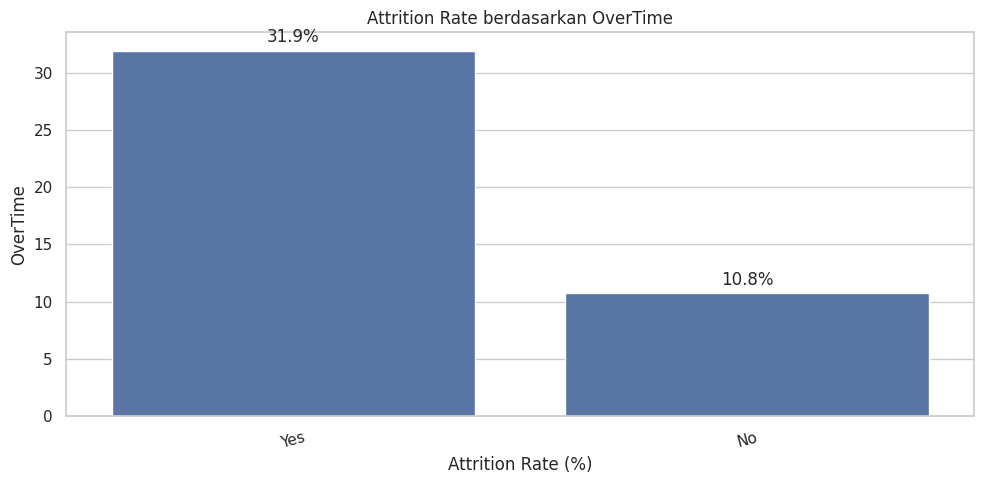

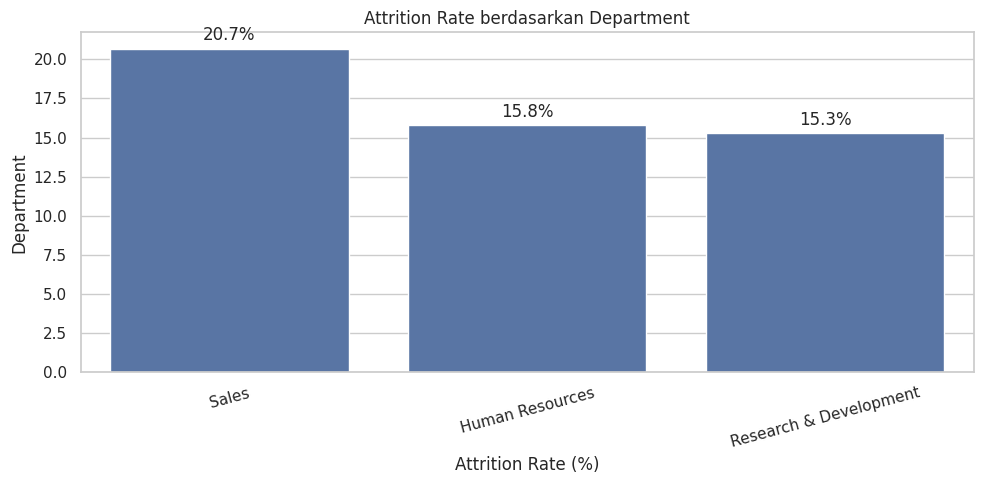

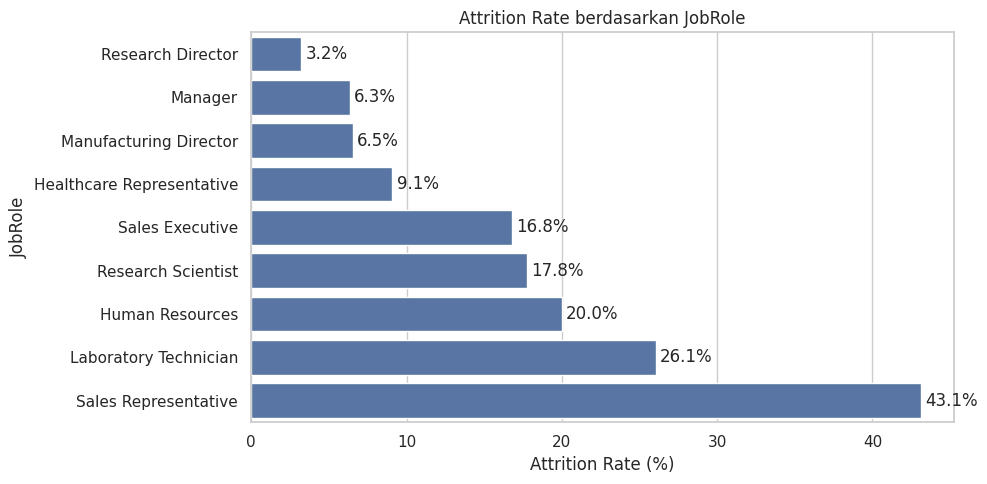

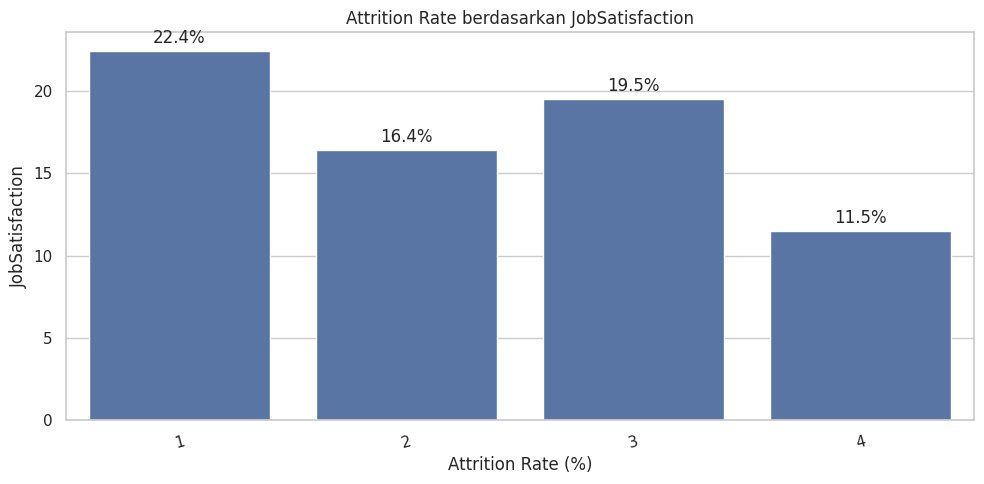

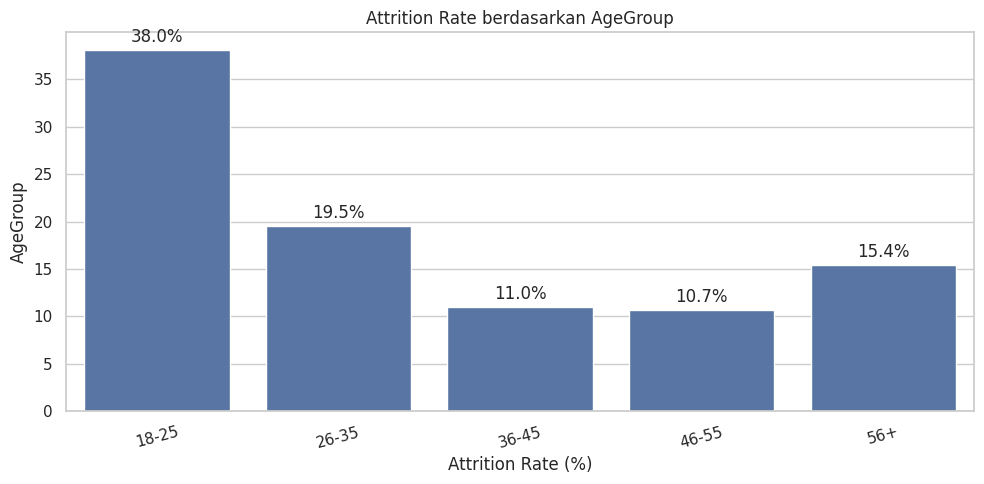

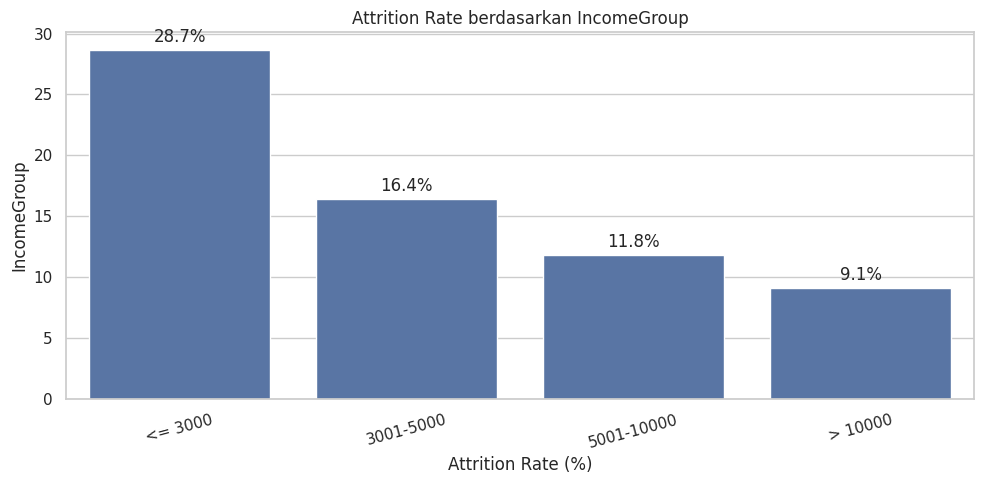

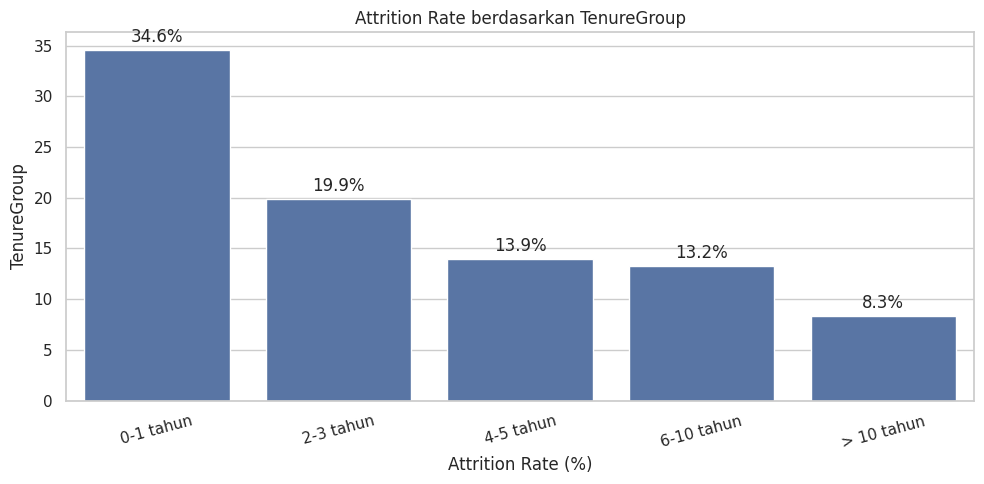

In [ ]:
main_plot_columns = [
    "OverTime",
    "Department",
    "JobRole",
    "JobSatisfaction",
    "AgeGroup",
    "IncomeGroup",
    "TenureGroup"
]

for col in main_plot_columns:
    if col not in categorical_summaries:
        continue

    summary = categorical_summaries[col]

    plt.figure(figsize=(10, 5))

    if summary[col].nunique(dropna=False) > 6:
        summary_plot = summary.sort_values(
            "Attrition_Rate_Persen",
            ascending=True
        )

        ax = sns.barplot(
            data=summary_plot,
            y=col,
            x="Attrition_Rate_Persen"
        )

        ax.bar_label(
            ax.containers[0],
            fmt="%.1f%%",
            padding=3
        )
    else:
        ax = sns.barplot(
            data=summary,
            x=col,
            y="Attrition_Rate_Persen"
        )

        ax.bar_label(
            ax.containers[0],
            fmt="%.1f%%",
            padding=3
        )

        plt.xticks(rotation=15)

    plt.title(f"Attrition Rate berdasarkan {col}")
    plt.xlabel("Attrition Rate (%)")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()


**Insight:**

* **Pemicu Utama dari Sisi Beban Kerja & Mobilitas:** Karyawan yang melakukan kerja lembur (**OverTime: Yes**) memiliki tingkat kelolaan yang sangat kritis sebesar **31.92%**. Tren serupa terlihat pada karyawan yang sering melakukan perjalanan dinas (**Travel_Frequently**) dengan angka attrition mencapai **24.88%**.
* **Kerapuhan pada Karyawan Muda dan Masa Kerja Awal:** Kelompok usia muda **18-25 tahun** mencatatkan angka attrition tertinggi sebesar **38.04%**. Pola ini diperkuat oleh metrik masa kerja (**TenureGroup**), di mana karyawan baru dengan masa kerja **0-1 tahun** memiliki attrition rate sebesar **34.59%**, menunjukkan adanya masalah pada proses onboarding atau adaptasi budaya kerja.
* **Kompensasi dan Jabatan Rendah Lebih Rentan:** Karyawan dengan pendapatan rendah (**Income <= 3000**) memiliki attrition rate **28.67%**, dan karyawan di level jabatan dasar (**JobLevel 1**) berada di angka **27.41%**. Sebaliknya, kelompok pendapatan tinggi (> 10000) dan JobLevel 4-5 jauh lebih stabil dengan tingkat keluar di bawah 10%.
* **Posisi Spesifik dengan Risiko Ekstrem:** Peran **Sales Representative** menjadi posisi paling tidak stabil dengan tingkat attrition luar biasa tinggi, yaitu **43.10%**, disusul oleh **Laboratory Technician (26.06%)**. Departemen **Sales** secara keseluruhan memimpin kepindahan ini dengan angka **20.69%**.
* **Faktor Psikologis dan Kepuasan Kerja:** Karyawan yang melaporkan kepuasan lingkungan (**EnvironmentSatisfaction 1**: **27.27%**), keterlibatan kerja rendah (**JobInvolvement 1**: **40.00%**), kepuasan kerja rendah (**JobSatisfaction 1**: **22.44%**), serta keseimbangan hidup yang buruk (**WorkLifeBalance 1**: **32.14%**) memiliki kecenderungan keluar yang jauh lebih tinggi dibanding rekan-rekan mereka yang merasa puas.
* **Pengaruh Fasilitas Finansial Jangka Panjang:** Kepemilikan saham perusahaan terbukti menjadi jangkar retensi yang kuat. Karyawan yang tidak memiliki opsi saham sama sekali (**StockOptionLevel 0**) mencatatkan attrition rate sebesar **25.69%**, sedangkan mereka yang memiliki opsi saham (Level 1 & 2) tingkat attrition-nya berhasil ditekan hingga di bawah 10%.


 EDA NUMERIK


--- Rata-rata Fitur Numerik berdasarkan Attrition ---


Attrition,Tidak Keluar,Keluar,Selisih
Age,37.79,33.47,-4.32
DailyRate,819.12,762.50,-56.62
DistanceFromHome,8.70,10.37,1.67
HourlyRate,65.80,64.85,-0.95
MonthlyIncome,6982.93,4872.94,-2109.99
MonthlyRate,14193.21,14631.01,437.80
NumCompaniesWorked,2.66,2.92,0.25
PercentSalaryHike,15.15,15.20,0.05
TotalWorkingYears,12.08,8.29,-3.79
TrainingTimesLastYear,2.80,2.63,-0.17


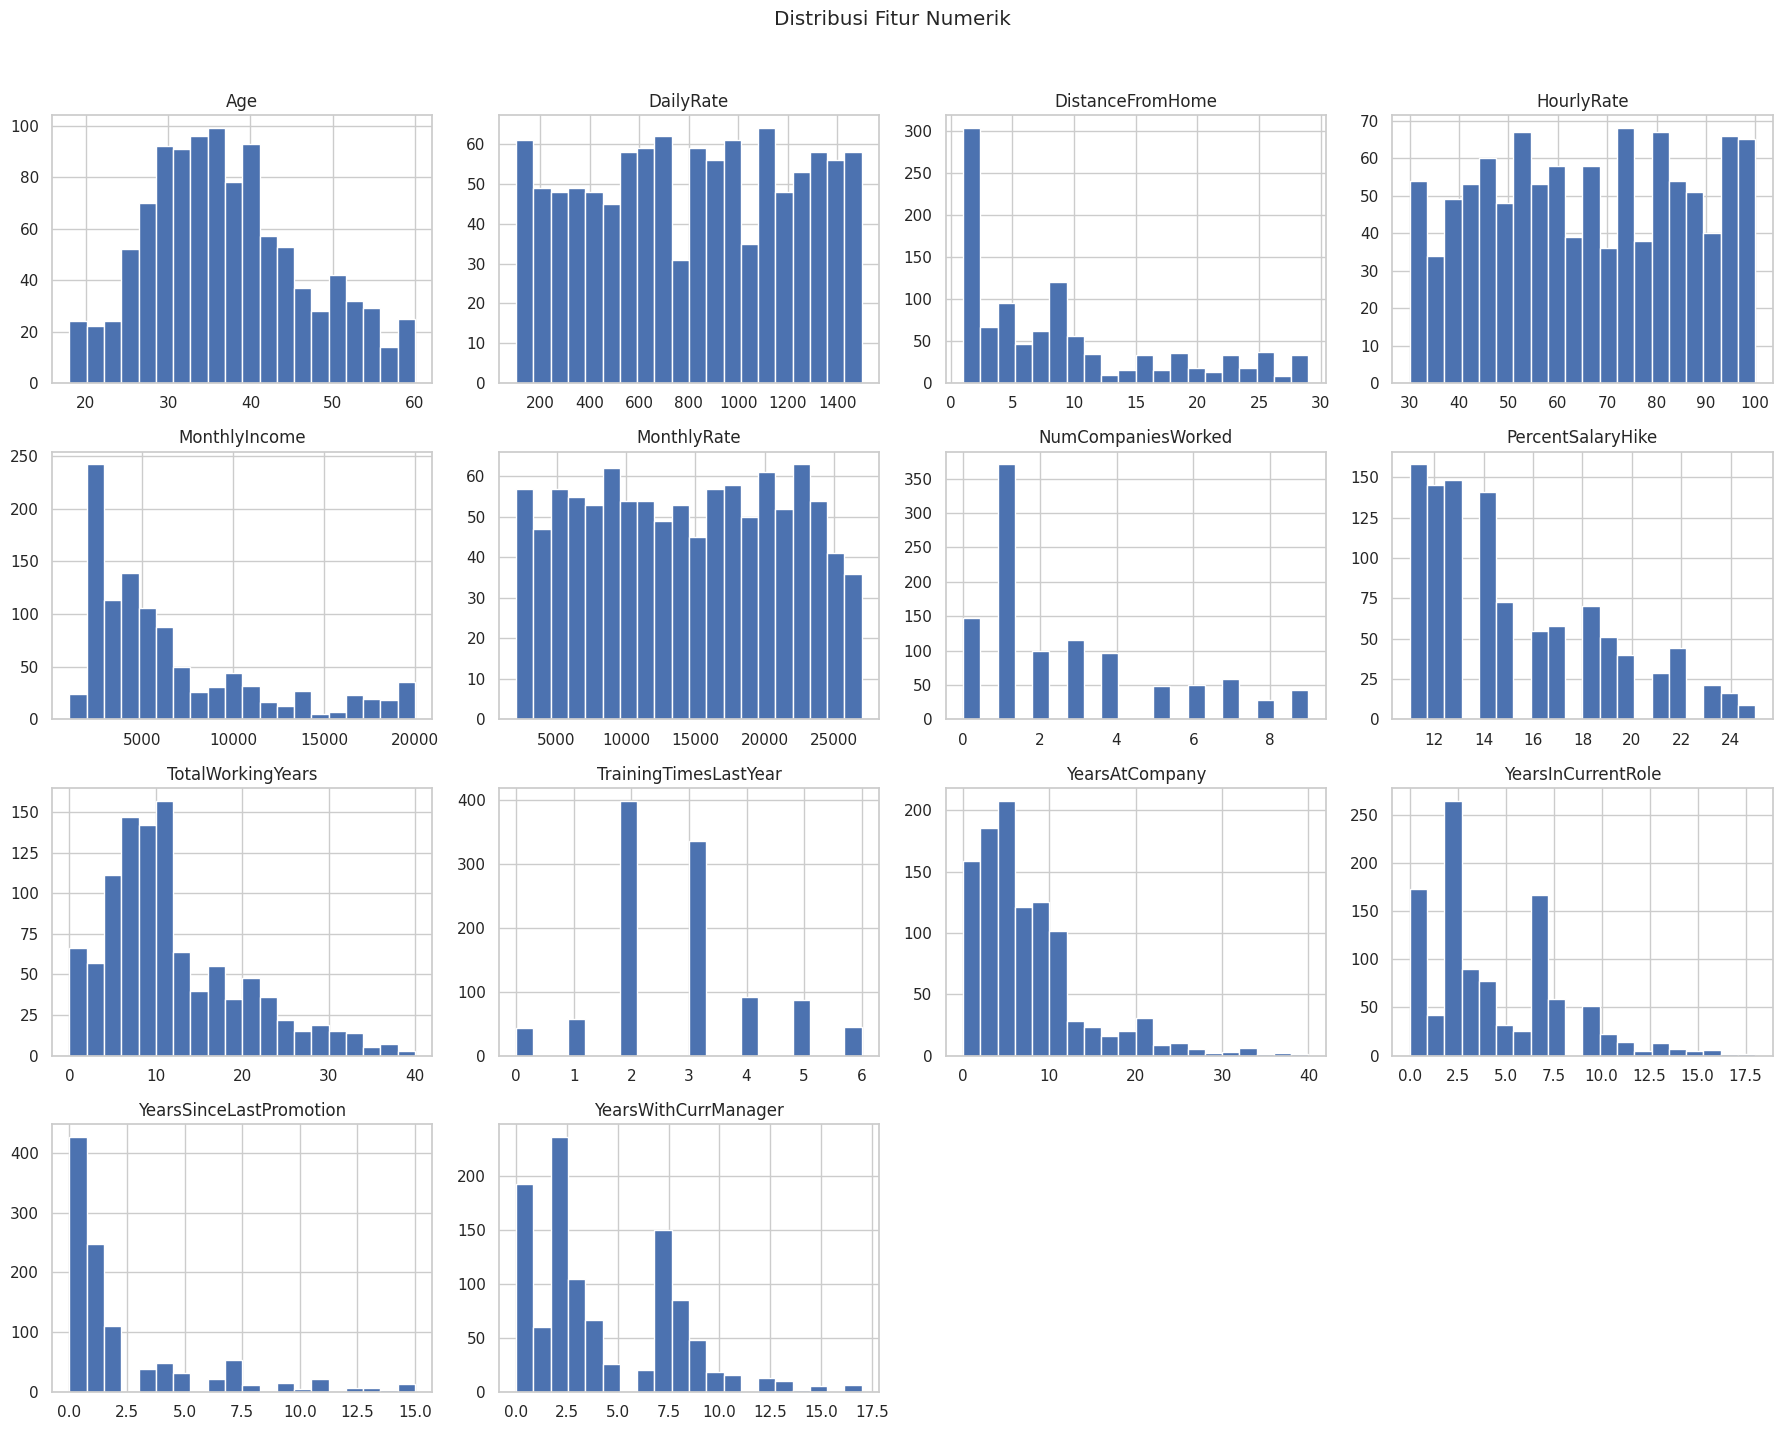

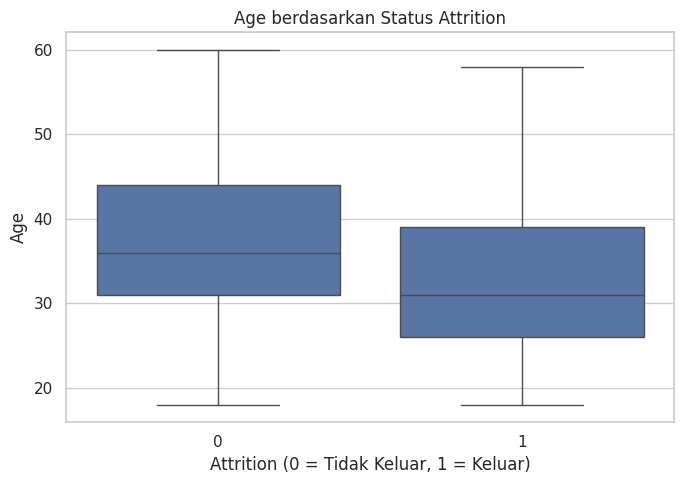

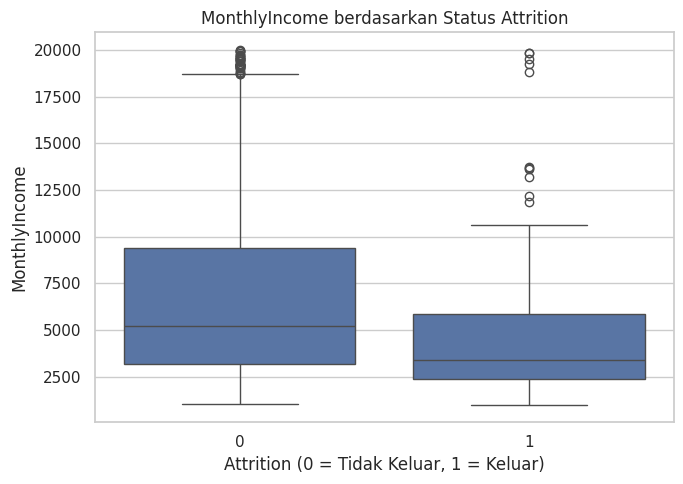

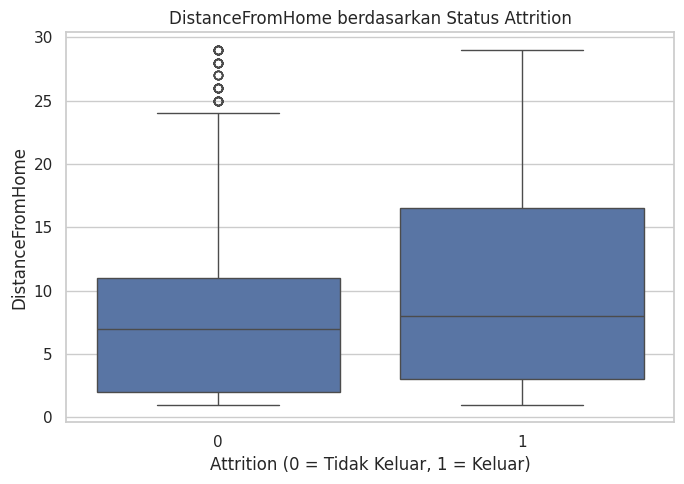

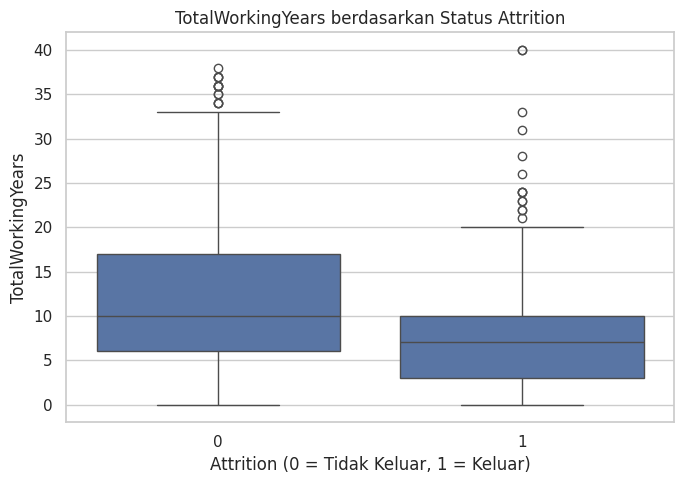

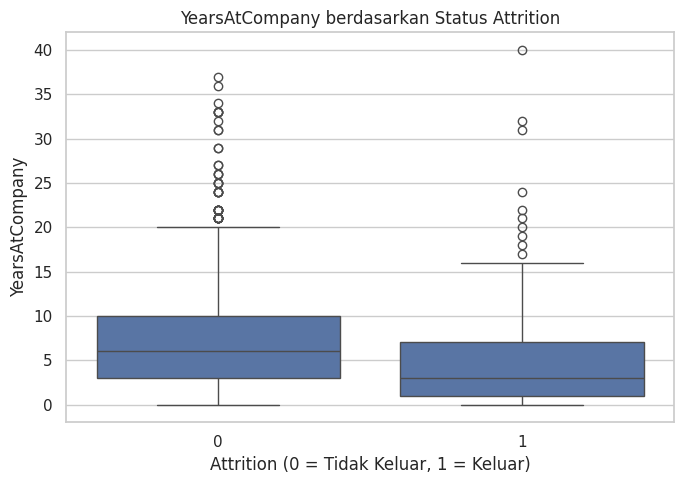

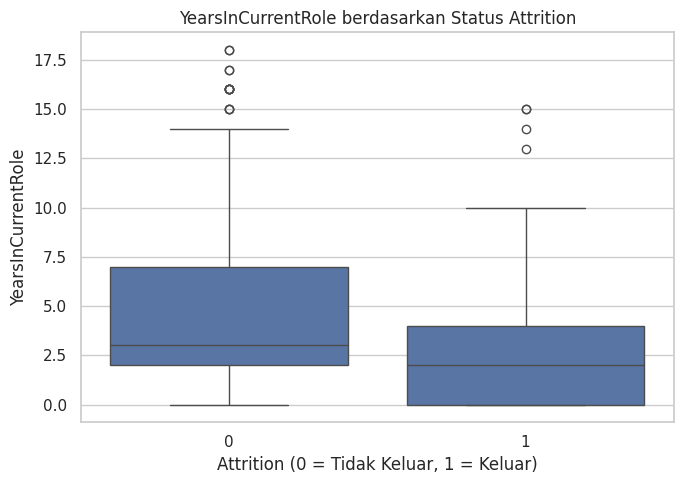

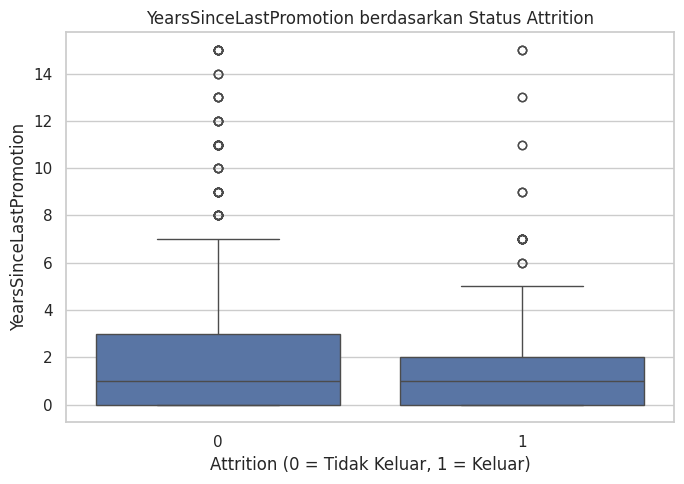

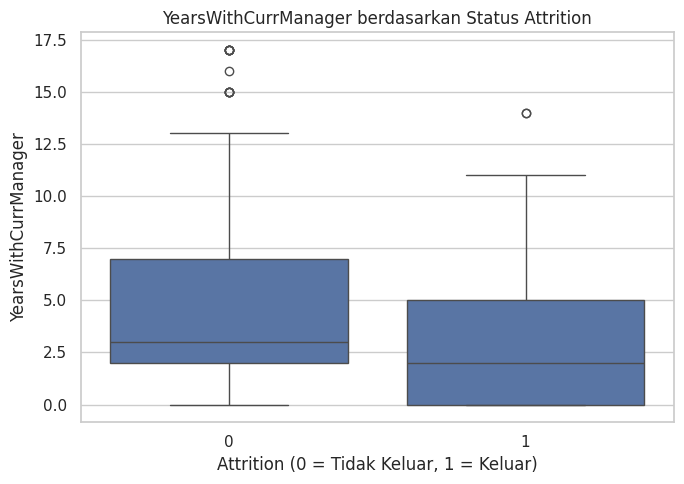

In [ ]:
numeric_columns = df_eda.select_dtypes(
    include=np.number
).columns.tolist()

numeric_features_eda = [
    col for col in numeric_columns
    if col not in ["Attrition", "EmployeeId"]
    and col not in ordinal_columns
    and df_eda[col].nunique(dropna=True) > 1
]

print("\n--- Rata-rata Fitur Numerik berdasarkan Attrition ---")

numeric_comparison = (
    df_eda.groupby("Attrition")[numeric_features_eda]
    .mean()
    .T
    .rename(columns={
        0: "Tidak Keluar",
        1: "Keluar"
    })
)

numeric_comparison["Selisih"] = (
    numeric_comparison["Keluar"]
    - numeric_comparison["Tidak Keluar"]
)

display(numeric_comparison.round(2))


# Histogram fitur numerik dalam satu rangkaian visualisasi.
if numeric_features_eda:
    df_eda[numeric_features_eda].hist(
        figsize=(18, 14),
        bins=20
    )

    plt.suptitle(
        "Distribusi Fitur Numerik",
        y=1.02
    )
    plt.tight_layout()
    plt.show()


# Boxplot untuk fitur numerik yang relevan dengan HR.
boxplot_columns = [
    "Age",
    "MonthlyIncome",
    "DistanceFromHome",
    "TotalWorkingYears",
    "YearsAtCompany",
    "YearsInCurrentRole",
    "YearsSinceLastPromotion",
    "YearsWithCurrManager"
]

boxplot_columns = [
    col for col in boxplot_columns
    if col in df_eda.columns
]

for col in boxplot_columns:
    plt.figure(figsize=(7, 5))

    sns.boxplot(
        data=df_eda,
        x="Attrition",
        y=col
    )

    plt.title(f"{col} berdasarkan Status Attrition")
    plt.xlabel("Attrition (0 = Tidak Keluar, 1 = Keluar)")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()


**Insight:**

* **Distribusi Fitur Mayoritas Skewed Positif:** Sebagian besar fitur numerik terkait durasi dan finansial seperti **MonthlyIncome**, **DistanceFromHome**, **YearsAtCompany**, **YearsInCurrentRole**, dan **YearsWithCurrManager** memiliki bentuk distribusi menjulur ke kanan (*right-skewed*). Kondisi ini menandakan bahwa mayoritas karyawan berkumpul di area nilai-nilai yang rendah pada indikator-indikator tersebut.
* **Kesenjangan Pendapatan Bulanan yang Signifikan:** Variabel **MonthlyIncome** menunjukkan perbedaan rata-rata paling ekstrem, di mana karyawan yang keluar memiliki pendapatan rata-rata **$4,872.94**, atau lebih rendah sebesar **$2,109.99** dibandingkan mereka yang bertahan ($6,982.93). Hal ini menegaskan bahwa faktor kompensasi finansial langsung menjadi pendorong utama keputusan karyawan untuk mengundurkan diri.
* **Pengaruh Faktor Senioritas dan Jam Terbang:** Karyawan yang keluar cenderung memiliki usia lebih muda (rata-rata **33.47 tahun** vs 37.79 tahun) dan total masa kerja yang lebih singkat (**TotalWorkingYears: 8.29 tahun** vs 12.08 tahun). Fenomena ini mengindikasikan bahwa stabilitas karyawan meningkat seiring bertambahnya usia dan pengalaman kerja di industri.
* **Aspek Kedekatan Geografis dan Hubungan Kerja:** Jarak rumah ke kantor (**DistanceFromHome**) karyawan yang keluar rata-rata lebih jauh **1.67 km** daripada karyawan yang bertahan. Selain itu, mereka yang memutuskan hengkang memiliki masa kerja di bawah manajer yang sama (**YearsWithCurrManager**) yang lebih pendek (selisih **-1.50 tahun**), menunjukkan pentingnya kualitas hubungan kepemimpinan awal bagi retensi staf.
* **Fitur dengan Efek Minim terhadap Attrition:** Berdasarkan visualisasi seragam (*uniform distribution*) dan nilai selisih yang sangat tipis, fitur-fitur seperti **DailyRate**, **HourlyRate**, **MonthlyRate**, dan **PercentSalaryHike** tidak memperlihatkan variasi pola yang berarti antara kedua kelompok. Faktor-faktor ini cenderung memiliki pengaruh yang kecil atau bahkan tidak berdampak terhadap status loyalitas karyawan.


KORELASI FITUR NUMERIK

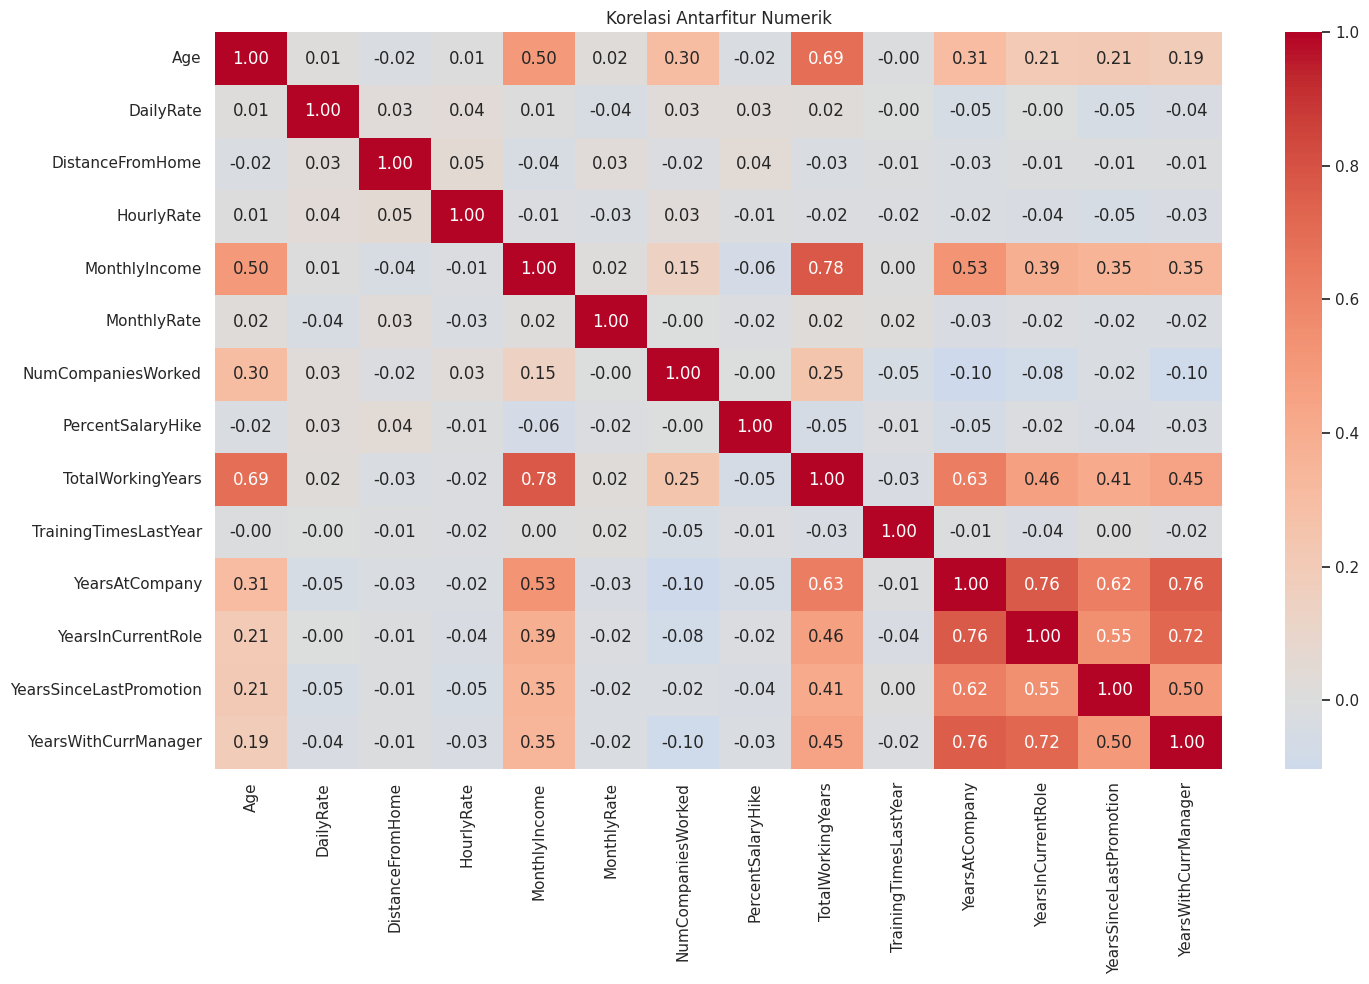

In [ ]:
correlation_columns = [
    col for col in numeric_features_eda
    if df_eda[col].nunique(dropna=True) > 1
]

if len(correlation_columns) >= 2:
    correlation_matrix = df_eda[
        correlation_columns
    ].corr()

    plt.figure(figsize=(15, 10))

    sns.heatmap(
        correlation_matrix,
        cmap="coolwarm",
        center=0,
        annot=True,
        fmt=".2f"
    )

    plt.title("Korelasi Antarfitur Numerik")
    plt.tight_layout()
    plt.show()


**Insight:**

* **Multikolinearitas Tinggi pada Fitur Pekerjaan:** Terdeteksi korelasi yang sangat kuat antara **YearsAtCompany** dengan **YearsInCurrentRole (0.76)** serta dengan **YearsWithCurrManager (0.76)**. Hubungan linear yang intens ini mengindikasikan adanya redundansi informasi (multikolinearitas) tinggi, sehingga perlu dipertimbangkan untuk melakukan seleksi fitur atau reduksi dimensi (seperti PCA) agar tidak mengganggu performa model berbasis regresi atau pohon.
* **Korelasi Finansial dan Pengalaman Kerja:** Pasangan variabel **MonthlyIncome** dan **TotalWorkingYears** menunjukkan nilai korelasi positif yang sangat signifikan sebesar **0.78**. Hal ini sangat logis secara bisnis karena menunjukkan bahwa struktur kompensasi di Jaya Jaya Maju berjalan berbanding lurus secara linier dengan akumulasi pengalaman profesional karyawan.
* **Hubungan Usia dengan Senioritas:** Fitur **Age** memiliki korelasi moderat hingga kuat dengan **TotalWorkingYears (0.69)** dan **MonthlyIncome (0.50)**. Angka ini memvalidasi pola data bahwa semakin matang usia seorang karyawan, semakin panjang rekam jejak kerja dan semakin tinggi tingkat pendapatan yang mereka terima di perusahaan.
* **Stagnasi vs Suksesi Kepemimpinan:** Terdapat korelasi yang kuat antara **YearsInCurrentRole** dengan **YearsWithCurrManager (0.72)**. Pola ini mengindikasikan bahwa ketika seorang karyawan tertahan lama di posisi yang sama, mereka cenderung terus di bawah kendali manajer yang sama, yang bisa memicu kejenuhan apabila tidak disertai penyegaran peran atau rotasi kerja.
* **Karakteristik Fitur Independen yang Ortogonal:** Mayoritas variabel operasional harian seperti **DailyRate**, **HourlyRate**, **MonthlyRate**, dan **DistanceFromHome** memiliki nilai korelasi yang mendekati nol (-0.05 hingga 0.05) terhadap semua fitur lainnya. Hal ini menandakan bahwa fitur-fitur tersebut bersifat independen satu sama lain dan membawa informasi unik tersendiri di dalam dataset.



ANALISIS KOMBINASI DUA FAKTOR

In [ ]:
if {
    "OverTime",
    "JobSatisfaction"
}.issubset(df_eda.columns):

    overtime_satisfaction = (
        df_eda.groupby(
            ["OverTime", "JobSatisfaction"],
            dropna=False,
            observed=False
        )
        .agg(
            Total_Karyawan=("Attrition", "size"),
            Karyawan_Keluar=("Attrition", "sum")
        )
        .reset_index()
    )

    overtime_satisfaction["Attrition_Rate_Persen"] = (
        overtime_satisfaction["Karyawan_Keluar"]
        / overtime_satisfaction["Total_Karyawan"]
        * 100
    ).round(2)

    print("\n--- Attrition: Lembur dan Kepuasan Kerja ---")
    display(
        overtime_satisfaction.sort_values(
            "Attrition_Rate_Persen",
            ascending=False
        )
    )



--- Attrition: Lembur dan Kepuasan Kerja ---


,OverTime,JobSatisfaction,Total_Karyawan,Karyawan_Keluar,Attrition_Rate_Persen
6,Yes,3,90,36,40.00
5,Yes,2,54,20,37.04
4,Yes,1,63,20,31.75
7,Yes,4,100,22,22.00
0,No,1,142,26,18.31
2,No,3,228,26,11.40
1,No,2,141,12,8.51
3,No,4,240,17,7.08


**Insight:**

* **Efek Ganda Lembur dan Ketidakpuasan Kerja (Kondisi Paling Kritis):** Karyawan yang harus bekerja lembur (**OverTime: Yes**) sekaligus memiliki tingkat kepuasan kerja sangat rendah (**JobSatisfaction 1**) mencatatkan angka pengunduran diri tertinggi dan sangat ekstrem, yaitu sebesar **40.00%**. Kombinasi kedua faktor ini menjadi pemicu paling destruktif bagi retensi karyawan di perusahaan.
* **Lembur Merusak Loyalitas Karyawan yang Puas:** Kebijakan lembur terbukti mampu mengikis efek positif dari kepuasan kerja. Karyawan yang merasa sangat puas dengan pekerjaannya (**JobSatisfaction 4**) namun tetap diwajibkan lembur, memiliki tingkat attrition yang masih cukup tinggi, yaitu **22.00%**. Angka ini jauh melebihi ambang batas toleransi perusahaan yang sebesar 10%.
* **Tanpa Lembur, Loyalitas Terjaga Optimal:** Kelompok karyawan yang tidak dibebani kerja lembur (**OverTime: No**) menunjukkan kestabilan yang jauh lebih baik. Karyawan tanpa lembur yang memiliki tingkat kepuasan kerja moderat hingga sangat tinggi (JobSatisfaction 3 & 4) mencatatkan tingkat attrition paling aman dan rendah, masing-masing hanya sebesar **11.40%** dan **7.08%**.
* **Prioritas Intervensi Manajemen HR:** Data ini memberikan arah yang jelas bagi departemen HR untuk segera memprioritaskan program retensi. Fokus utama harus ditargetkan pada pengurangan beban kerja berlebih (lembur) dan peningkatan kenyamanan kerja bagi kelompok karyawan di level kepuasan 1, 2, dan 3 yang saat ini diwajibkan lembur, karena angka attrition mereka semuanya berada di zona merah (di atas 31%).


 MENYIMPAN RINGKASAN UNTUK DASHBOARD

In [ ]:
dashboard_summary = pd.concat(
    [
        summary.assign(Faktor=column)
        for column, summary in categorical_summaries.items()
    ],
    ignore_index=True
)

dashboard_summary.to_csv(
    "attrition_dashboard_summary.csv",
    index=False
)

print(
    "\nRingkasan dashboard disimpan:",
    "attrition_dashboard_summary.csv"
)



Ringkasan dashboard disimpan: attrition_dashboard_summary.csv


## Modeling



In [ ]:
df_model = df.loc[
    df["Attrition"].isin([0, 1])
].copy()

df_model["Attrition"] = df_model["Attrition"].astype(int)

# Hapus target, identifier, dan kolom konstan.
excluded_columns = ["Attrition"]

if "EmployeeId" in df_model.columns:
    excluded_columns.append("EmployeeId")

constant_model_columns = [
    col for col in df_model.columns
    if df_model[col].nunique(dropna=False) <= 1
]

excluded_columns = list(dict.fromkeys(
    excluded_columns + constant_model_columns
))

X = df_model.drop(
    columns=excluded_columns,
    errors="ignore"
)

y = df_model["Attrition"]

if y.nunique() != 2:
    raise ValueError(
        "Target Attrition harus memiliki kelas 0 dan 1."
    )

print("\n--- Data Modeling ---")
print("Jumlah data:", len(X))
print("Jumlah fitur:", X.shape[1])
print("\nDistribusi target:")
display(y.value_counts().sort_index())



--- Data Modeling ---
Jumlah data: 1058
Jumlah fitur: 30

Distribusi target:


,count
Attrition,
0,879
1,179


TRAIN / VALIDATION / TEST SPLIT

In [ ]:
# 60% train, 20% validation, 20% test.
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.25,
    random_state=42,
    stratify=y_train_val
)

print("Data train:", len(X_train))
print("Data validation:", len(X_val))
print("Data test:", len(X_test))


Data train: 634
Data validation: 212
Data test: 212


**Insight:**

* **Strategi Pembagian Data yang Tepat (Stratified Splitting):** Pembagian dataset menjadi **60% Train (634 data), 20% Validation (212 data), dan 20% Test (212 data)** dilakukan dengan menggunakan parameter `stratify=y`. Pendekatan ini memastikan rasio kelas attrition (karyawan keluar vs bertahan) tetap konsisten dan seimbang di setiap sub-dataset, menghindari risiko bias saat evaluasi model.

PREPROCESSING PIPELINE

In [ ]:
# Gunakan OneHotEncoder untuk fitur kategori dan ordinal.
categorical_model_columns = list(dict.fromkeys(
    [
        col for col in X.columns
        if (
            X[col].dtype == "object"
            or str(X[col].dtype) == "category"
            or X[col].dtype == "bool"
        )
    ]
    + [col for col in ordinal_columns if col in X.columns]
))

numeric_model_columns = [
    col for col in X.columns
    if col not in categorical_model_columns
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

transformers = []

if numeric_model_columns:
    transformers.append((
        "num",
        numeric_transformer,
        numeric_model_columns
    ))

if categorical_model_columns:
    transformers.append((
        "cat",
        categorical_transformer,
        categorical_model_columns
    ))

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

print("\nFitur numerik:", numeric_model_columns)
print("Fitur kategorikal:", categorical_model_columns)




Fitur numerik: ['Age', 'DailyRate', 'DistanceFromHome', 'HourlyRate', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'TotalWorkingYears', 'TrainingTimesLastYear', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']
Fitur kategorikal: ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime', 'Education', 'EnvironmentSatisfaction', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'WorkLifeBalance']


**Insight:**


* **Reduksi Dimensi Melalui Pembersihan Fitur:** Langkah pembersihan berhasil mereduksi jumlah dimensi dari total **35 fitur awal menjadi 30 fitur terpilih**. Penghapusan fitur konstan (`EmployeeCount`, `Over18`, `StandardHours`) dan kolom identitas (`EmployeeId`) secara langsung meningkatkan efisiensi komputasi model.
* **Pemisahan Jalur Preprocessing yang Jelas (Pipeline Robustness):** Arsitektur `ColumnTransformer` memisahkan data dengan cermat menjadi **14 fitur numerik** dan **16 fitur kategorikal** (termasuk fitur berskala ordinal). Penggunaan `SimpleImputer` dengan strategi median dan modus bertindak sebagai jaring pengaman (*fail-safe*) yang sangat baik jika di masa depan terdapat data baru yang kosong.
* **Penanganan Fitur Ordinal Sebagai Kategorikal:** Memasukkan fitur-fitur tingkat kepuasan dan penilaian (seperti `JobSatisfaction`, `EnvironmentSatisfaction`, dan `JobLevel`) ke dalam kategori yang di-encode menggunakan `OneHotEncoder` merupakan langkah cerdas. Hal ini membebaskan model dari asumsi linieritas kaku yang biasa terjadi jika fitur ordinal dipaksakan bertipe numerik kontinu.



TRAINING DAN PEMILIHAN MODEL

In [ ]:
model_candidates = {
    "Dummy Baseline": DummyClassifier(
        strategy="most_frequent"
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}


def create_pipeline(classifier):
    """Membuat pipeline baru untuk setiap model."""

    return Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", clone(classifier))
    ])


validation_results = []
validation_models = {}

for model_name, classifier in model_candidates.items():

    pipeline = create_pipeline(classifier)

    pipeline.fit(X_train, y_train)

    y_val_pred = pipeline.predict(X_val)

    result = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, y_val_pred),
        "Precision": precision_score(
            y_val,
            y_val_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_val,
            y_val_pred,
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_val,
            y_val_pred,
            zero_division=0
        )
    }

    if hasattr(pipeline, "predict_proba"):
        y_val_prob = pipeline.predict_proba(X_val)[:, 1]

        result["ROC-AUC"] = roc_auc_score(
            y_val,
            y_val_prob
        )
    else:
        result["ROC-AUC"] = np.nan

    validation_results.append(result)
    validation_models[model_name] = pipeline


validation_results_df = (
    pd.DataFrame(validation_results)
    .sort_values("F1-Score", ascending=False)
    .reset_index(drop=True)
)

print("\n--- Perbandingan Model pada Validation Set ---")
display(validation_results_df.round(4))

best_model_name = validation_results_df.iloc[0]["Model"]

print("\nModel terpilih:", best_model_name)



--- Perbandingan Model pada Validation Set ---


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8113,0.4677,0.8056,0.5918,0.8529
1,Random Forest,0.8538,0.7273,0.2222,0.3404,0.7885
2,Dummy Baseline,0.8302,0.0000,0.0000,0.0000,0.5000



Model terpilih: Logistic Regression


**Insight:**

* **Keunggulan Telak Logistic Regression pada Deteksi Attrition:** Model **Logistic Regression** terpilih sebagai model terbaik karena menghasilkan **F1-Score tertinggi sebesar 0.5918** dan nilai **ROC-AUC yang sangat kuat (0.8529)**. Model ini menunjukkan kemampuan membedakan pola karyawan yang akan keluar vs bertahan secara optimal pada data validasi.
* **Recall Tinggi untuk Mitigasi Risiko Bisnis:** Penerapan parameter `class_weight="balanced"` pada Logistic Regression berhasil memberikan tingkat **Recall sebesar 80.56%**. Bagi departemen HR, metrik ini sangat krusial karena artinya model mampu mendeteksi sekitar 80% dari total karyawan yang sebenarnya berisiko keluar, meminimalkan peluang adanya karyawan *resign* yang luput dari pantauan (*false negatives*).
* **Kelemahan Model Random Forest Akibat Imbalance Data:** Meskipun **Random Forest** mencatatkan akurasi umum yang lebih tinggi (85.38%) dan Precision yang baik (72.73%), model ini gagal total dalam mengenali sinyal attrition dengan **Recall yang sangat rendah, yaitu hanya 22.22%**. Hal ini menunjukkan bahwa algoritma berbasis pohon (*tree-based*) cenderung kesulitan mempelajari kelas minoritas jika tidak didukung oleh teknik penyeimbangan data yang lebih agresif seperti SMOTE.
* **Dummy Baseline Sebagai Tolok Ukur Validitas:** Nilai **F1-Score 0.0000** pada **Dummy Baseline** memvalidasi bahwa performa prediksi yang dihasilkan oleh model Logistic Regression dan Random Forest bukanlah hasil kebetulan semata (*random guessing*), melainkan murni bersumber dari hasil pembelajaran pola data historis karyawan.


## Evaluation

TRAIN ULANG DAN EVALUASI AKHIR


--- Evaluasi Akhir pada Test Set ---


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.7358,0.3611,0.7222,0.4815,0.8305



--- Classification Report ---
              precision    recall  f1-score   support

Tidak Keluar       0.93      0.74      0.82       176
      Keluar       0.36      0.72      0.48        36

    accuracy                           0.74       212
   macro avg       0.64      0.73      0.65       212
weighted avg       0.83      0.74      0.76       212



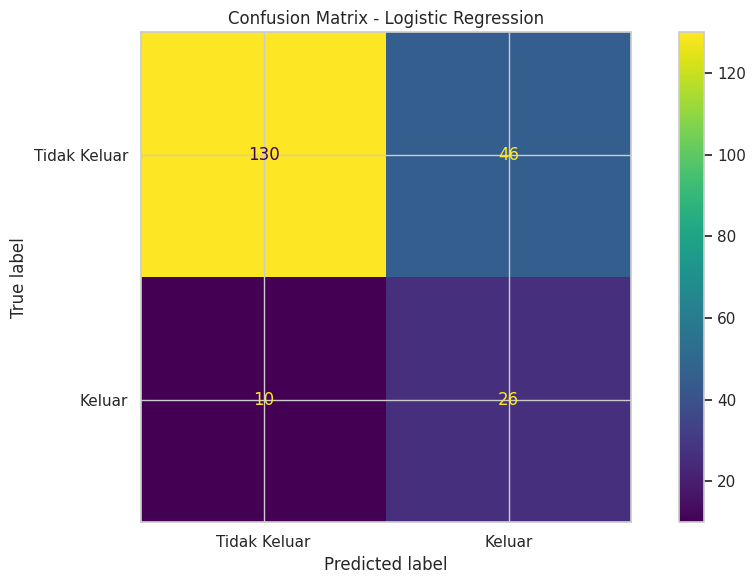

In [ ]:
# Setelah model dipilih, latih ulang dengan train + validation.
best_classifier = model_candidates[best_model_name]

best_model = create_pipeline(best_classifier)

best_model.fit(X_train_val, y_train_val)

y_test_pred = best_model.predict(X_test)

print("\n--- Evaluasi Akhir pada Test Set ---")

test_results = {
    "Model": best_model_name,
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision": precision_score(
        y_test,
        y_test_pred,
        zero_division=0
    ),
    "Recall": recall_score(
        y_test,
        y_test_pred,
        zero_division=0
    ),
    "F1-Score": f1_score(
        y_test,
        y_test_pred,
        zero_division=0
    )
}

if hasattr(best_model, "predict_proba"):
    y_test_prob = best_model.predict_proba(X_test)[:, 1]

    test_results["ROC-AUC"] = roc_auc_score(
        y_test,
        y_test_prob
    )

test_results_df = pd.DataFrame([test_results])

display(test_results_df.round(4))

print("\n--- Classification Report ---")

print(
    classification_report(
        y_test,
        y_test_pred,
        labels=[0, 1],
        target_names=["Tidak Keluar", "Keluar"],
        zero_division=0
    )
)


# Confusion matrix.
cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Tidak Keluar", "Keluar"]
)

disp.plot(values_format="d")
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()


**Insight:**

* **Kemampuan Generalisasi Model Cukup Stabil:** Pada data uji (*test set*), model Logistic Regression menghasilkan **Akurasi 73.58%** dan **ROC-AUC yang tetap kuat sebesar 0.8305**. Meskipun terjadi sedikit penurunan performa dibandingkan data validasi (*drop* pada F1-Score menjadi 0.4815), nilai ROC-AUC yang stabil di atas 0.80 membuktikan model memiliki pondasi yang baik dan tidak mengalami *overfitting* yang parah.
* **Recall Tinggi Berhasil Dipertahankan (Mitigasi Risiko Optimal):** Model berhasil mempertahankan tingkat **Recall sebesar 72.22%** (mampu mendeteksi **26 dari 36 karyawan yang asli keluar** berdasarkan *Confusion Matrix*). Dari sudut pandang HR, performa ini sangat bernilai karena meminimalkan jumlah karyawan berisiko yang luput dari radar intervensi (*False Negatives* hanya 10 orang).
* **Tantangan Biaya Efisiensi Akibat Low Precision:** Model menghasilkan **Precision sebesar 36.11%**, yang tercermin dari adanya **46 karyawan yang diprediksi akan keluar namun nyatanya bertahan** (*False Positives*). Dampak bisnisnya adalah departemen HR berpotensi mengalokasikan anggaran, waktu, dan program retensi (seperti kenaikan gaji atau insentif) kepada karyawan yang sebenarnya tidak berniat untuk *resign*.
* **Trade-off Keputusan Bisnis HR:** Tingginya angka *False Positives* (46) dibanding *False Negatives* (10) merupakan konsekuensi logis dari penggunaan bobot kelas seimbang (*balanced class weight*). Bagi Jaya Jaya Maju, *trade-off* ini dinilai lebih menguntungkan karena biaya untuk mempertahankan karyawan jauh lebih murah dibandingkan biaya operasional dan rekrutmen ulang akibat kecolongan karyawan kompeten yang mendadak keluar.


MENYIMPAN MODEL DAN HASIL EVALUASI

In [ ]:
os.makedirs("model", exist_ok=True)

model_artifact = {
    "model": best_model,
    "features": X.columns.tolist(),
    "model_name": best_model_name
}

model_path = "model/attrition_model.joblib"

joblib.dump(model_artifact, model_path)

print("\nModel disimpan:", model_path)
print(
    "Ukuran model:",
    round(os.path.getsize(model_path) / 1024, 2),
    "KB"
)

validation_results_df.to_csv(
    "model/model_validation_results.csv",
    index=False
)

test_results_df.to_csv(
    "model/model_test_results.csv",
    index=False
)

print("Hasil evaluasi berhasil disimpan.")


# Contoh input untuk pengujian prediction.py.
sample_input = X_test.iloc[[0]].copy()

sample_input.to_csv(
    "sample_employee.csv",
    index=False
)

print("Contoh input disimpan: sample_employee.csv")



Model disimpan: model/attrition_model.joblib
Ukuran model: 10.17 KB
Hasil evaluasi berhasil disimpan.
Contoh input disimpan: sample_employee.csv


MENYIAPKAN DATA DASHBOARD

In [ ]:
df_dashboard = df.copy()

# Status kosong tetap menjadi Tidak Diketahui.
df_dashboard["AttritionStatus"] = (
    df_dashboard["Attrition"]
    .map({
        0: "Tidak Keluar",
        1: "Keluar"
    })
    .fillna("Tidak Diketahui")
)

# Menandai apakah target diketahui.
df_dashboard["AttritionKnown"] = (
    df_dashboard["Attrition"]
    .isin([0, 1])
    .astype(int)
)

# Gunakan nilai kosong jika status karyawan tidak diketahui.
df_dashboard["EmployeeLeft"] = (
    df_dashboard["Attrition"]
    .map({0: 0, 1: 1})
)

df_dashboard = add_analysis_groups(df_dashboard)

df_dashboard.to_csv(
    "employee_dashboard.csv",
    index=False
)

print("\nData dashboard disimpan: employee_dashboard.csv")
print("\nDistribusi status dashboard:")
display(
    df_dashboard["AttritionStatus"]
    .value_counts(dropna=False)
)




Data dashboard disimpan: employee_dashboard.csv

Distribusi status dashboard:


,count
AttritionStatus,
Tidak Keluar,879
Tidak Diketahui,412
Keluar,179


RINGKASAN AKHIR

In [ ]:
print("\n" + "=" * 60)
print("RINGKASAN PROYEK")
print("=" * 60)

print("Ukuran dataset awal:", df.shape)
print("Data dengan label valid:", len(df_eda))
print(f"Attrition rate: {attrition_rate:.2f}%")
print("Model terpilih:", best_model_name)
print(
    "F1-score validation:",
    round(
        validation_results_df.iloc[0]["F1-Score"],
        4
    )
)
print(
    "F1-score test:",
    round(test_results["F1-Score"], 4)
)

print("\nFile yang dihasilkan:")
print("- attrition_dashboard_summary.csv")
print("- employee_dashboard.csv")
print("- model/attrition_model.joblib")
print("- model/model_validation_results.csv")
print("- model/model_test_results.csv")
print("- sample_employee.csv")


RINGKASAN PROYEK
Ukuran dataset awal: (1470, 35)
Data dengan label valid: 1058
Attrition rate: 16.92%
Model terpilih: Logistic Regression
F1-score validation: 0.5918
F1-score test: 0.4815

File yang dihasilkan:
- attrition_dashboard_summary.csv
- employee_dashboard.csv
- model/attrition_model.joblib
- model/model_validation_results.csv
- model/model_test_results.csv
- sample_employee.csv


## Conclusion

### 1. Masalah Utama (Key Findings dari EDA)
* **Krisis Attrition di Zona Merah:** Tingkat perputaran karyawan Jaya Jaya Maju mencapai **16.92%**, secara signifikan menembus batas toleransi aman yang ditetapkan departemen HR sebesar **10%**.
* **Beban Kerja Berlebih & Mobilitas Tinggi:** Kebijakan kerja lembur menjadi pemicu paling merusak dengan angka attrition mencapai **31.92%**. Kondisi ini diperparah jika karyawan juga sering melakukan perjalanan dinas (**24.88%**).
* **Kerapuhan Generasi Baru (Early Tenure):** Karyawan dengan masa kerja **0-1 tahun** memiliki tingkat keluar yang sangat ekstrem sebesar **34.59%**, serta kelompok usia muda **18-25 tahun** mencapai **38.04%**. Ini mengindikasikan adanya masalah besar pada proses orientasi (*onboarding*) atau adaptasi kultur.
* **Kesenjangan Kompensasi & Jabatan Rendah:** Karyawan dengan pendapatan rendah (**<= $3,000**) mencatatkan attrition sebesar **28.67%**. Ada selisih pendapatan rata-rata yang sangat besar (**$2,109.99**) antara karyawan yang keluar dengan yang bertahan.
* **Titik Kritis pada Posisi Spesifik:** Peran **Sales Representative** berada dalam kondisi paling tidak stabil dengan tingkat attrition mencapai **43.10%**, disusul oleh posisi **Laboratory Technician** sebesar **26.06%**.
* **Dampak Kelelahan Mental & Fasilitas Saham:** Karyawan yang mengeluhkan keseimbangan hidup buruk (**WorkLifeBalance Level 1**) memiliki tingkat attrition **32.14%**. Sebaliknya, pemberian opsi kepemilikan saham (**Stock Option**) terbukti menjadi jangkar retensi yang sangat kuat untuk menekan angka *resign* hingga di bawah 10%.

---

### 2. Key Performance Indicators (KPI) untuk Dashboard
Untuk memantau kondisi ini secara *real-time*, komponen *dashboard* wajib menampilkan metrik berikut:
* **KPI Utama (Top Cards):** Total Karyawan Aktif, Angka Attrition Keseluruhan (% Attrition Rate), Total Biaya Estimasi Rekrutmen (Loss Metric), dan Total Karyawan Lembur.
* **Grafik Tren/Distribusi (Charts):**
  * *Bar Chart:* Attrition Rate berdasarkan Kebijakan Lembur (*Overtime Status*).
  * *Donut/Pie Chart:* Proporsi Attrition berdasarkan Kelompok Masa Kerja (*Tenure Group*).
  * *Horizontal Bar Chart:* Attrition Rate berdasarkan Peran Jabatan (*Job Role*).
  * *Scatter Plot / Heatmap:* Hubungan antara Tingkat Kepuasan Kerja (*Job Satisfaction*) vs Pendapatan Bulanan (*Monthly Income*).

---

### 3. Rekomendasi Aksi Bagi Departemen HR
* **Restrukturisasi Kebijakan Lembur & Beban Kerja:** Melakukan audit jam kerja pada divisi dengan tingkat lembur tinggi. Memberikan insentif yang adil atau menerapkan sistem libur pengganti (*compensated time off*) untuk menjaga *work-life balance*.
* **Evaluasi Struktur Kompensasi Level Dasar:** Meninjau kembali standar gaji minimum (khususnya untuk pendapatan <= $3,000) dan memperluas cakupan fasilitas *Stock Option* ke level jabatan yang lebih rendah guna mengikat loyalitas jangka panjang.
* **Penyegaran Program Onboarding & Mentorship:** Memperbaiki sistem orientasi pada 12 bulan pertama kerja. Memasangkan karyawan baru (terutama usia 18-25 tahun) dengan mentor senior untuk menekan angka *early attrition*.
* **Intervensi Khusus pada Tim Sales & Laboratorium:** Memberikan perhatian khusus pada peran *Sales Representative* melalui penyesuaian target penjualan yang lebih realistis, perbaikan jalur karier (*clear career path*), serta pelatihan manajemen stres.
